# Ideal-spectrum RV recovery

<span style="color:red">The HISPEC DRP is in active development. Please submit issues and suggestions on the [GitHub](https://github.com/oirlab/HISPEC_DRP).</span>

From the rest-frame **BT-Settl lte040** (4000 K) template, we simulate an
**LSF-matched** BSPEC L2 (HDF PSF→1-D LSF after paint) then recover its injected
RV with the matched `*.lsf.ccfopt.delta.mas` line mask and `StellarRVPrimitive`.
In this example, this is done for injected RVs from 0-50 km/s in steps of 10 km/s
and the injected versus recovered RVs are plotted at the end, including the
recovered RV uncertainty and residual.

Build the full-band LSF mask first with `build_ccfopt_mask_ideal_spectrum`
(or copy that `*.lsf.ccfopt.delta.mas` into `OUT`). The packaged
`lte040...lsf.ccfopt.delta.mas` is a two-order smoke file only.


In [1]:
from pathlib import Path

import hispecdrp

print(f"hispecdrp {hispecdrp.__version__} @ {hispecdrp.__file__}")

OUT = Path("/path/to/ideal_spectrum_rv_recovery")
OUT.mkdir(parents=True, exist_ok=True)
print("output:", OUT.resolve())


hispecdrp 0.0.post109+gf8dfcb577.d20260828 @ /Users/ckilpatrick/Dropbox/scripts/python/cursor/HISPEC_DRP/hispecdrp/__init__.py
output: /Users/ckilpatrick/ideal_spectrum_rv_recovery


## 1. Configure template and mask

Packaged lte040 template and an **LSF-matched** `*.lsf.ccfopt.delta.mas` line
mask. Recovery uses ccfopt line-by-line defaults on the full BSPEC echelle
range. Prefer the mask written by `build_ccfopt_mask_ideal_spectrum`; the
`paired_line_mask_path_for_template` fallback is the packaged smoke product.


In [2]:
from hispecdrp.utils.line_mask_utils import paired_line_mask_path_for_template

FIBER = 1
BULK_RV_KM_S = [0.0, 10.0, 20.0, 30.0, 40.0, 50.0]
TEMPLATE = "lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.h5"
APPLY_LSF = True
MASK_STEM = Path(TEMPLATE).stem + ".lsf.ccfopt.delta.mas"
MASK_LOCAL = OUT / MASK_STEM
if MASK_LOCAL.is_file():
    MASK_PATH = str(MASK_LOCAL)
else:
    MASK_PATH = paired_line_mask_path_for_template(
        TEMPLATE, mask_style="lsf.ccfopt.delta"
    )

print(f"mask: {MASK_PATH}")


mask: /Users/ckilpatrick/ideal_spectrum_rv_recovery/lte040.0-4.5-0.0a+0.0.BT-Settl.spec.7.lsf.ccfopt.delta.mas


## 2. Inject, recover, and collate

For each bulk shift, `build_l2(..., apply_lsf=True)` injects the template into a
BSPEC L2 and convolves with the HDF LSF, then `recover_stellar_rv` runs the same
line-by-line `ccf_line_mask` path as `build_ccfopt_mask` (`IDEAL_SPECTRUM_STELLAR_RV_KW`).


In [3]:
import numpy as np

from hispecdrp.primitives import StellarRVPrimitive
from hispecdrp.simulations.spectra import build_l2, quiet_pipeline_logging

hdr = (
    f"{'bulk_km/s':>10}  {'injected_m/s':>14}  {'recovered_m/s':>16}  "
    f"{'rv_err_m/s':>12}  {'bias_m/s':>12}  {'bias_mm/s':>10}"
)
print(hdr)
print("-" * len(hdr))

inj_m_s = []
rec_m_s = []
err_m_s = []

# This suppresses logging from the pipeline so the output is cleaner
with quiet_pipeline_logging():
    for bulk in BULK_RV_KM_S:
        l2 = build_l2(
            bulk,
            template=TEMPLATE,
            fiber=FIBER,
            apply_lsf=APPLY_LSF,
        )
        inj = float(bulk) * 1000.0
        out = StellarRVPrimitive.call(
            l2,
            mask_path=str(MASK_PATH),
            ccf_input_velocity=inj,
        )
        avg = getattr(out, f"rvccfavg_fib{FIBER}")
        rec = float(avg["RV"][0])
        err = float(avg["RV_ERR"][0])
        bias = rec - inj
        inj_m_s.append(inj)
        rec_m_s.append(rec)
        err_m_s.append(err)
        print(
            f"{bulk:10.1f}  {inj:14.4f}  {rec:16.6f}  {err:12.6f}  "
            f"{bias:12.6e}  {bias * 1e3:10.4f}"
        )

inj_m_s = np.asarray(inj_m_s, dtype=float)
rec_m_s = np.asarray(rec_m_s, dtype=float)
err_m_s = np.asarray(err_m_s, dtype=float)
bias_m_s = rec_m_s - inj_m_s
max_abs = float(np.max(np.abs(bias_m_s)))
rms = float(np.sqrt(np.mean(bias_m_s**2)))
d_bias = bias_m_s - bias_m_s[0]
max_d = float(np.max(np.abs(d_bias[1:])))
print()
print(f"max|bias| = {max_abs:.6e} m/s ({max_abs * 1e3:.4f} mm/s)")
print(f"rms bias  = {rms:.6e} m/s ({rms * 1e3:.4f} mm/s)")
print(f"max|differential bias| (vs RV=0) = {max_d:.6e} m/s ({max_d * 1e3:.4f} mm/s)")


 bulk_km/s    injected_m/s     recovered_m/s    rv_err_m/s      bias_m/s   bias_mm/s
------------------------------------------------------------------------------------
       0.0          0.0000         -0.000001      0.000316  -1.223883e-06     -0.0012
      10.0      10000.0000       9999.924635      0.079385  -7.536484e-02    -75.3648
      20.0      20000.0000      19999.896196      0.078906  -1.038042e-01   -103.8042
      30.0      30000.0000      30000.048249      0.079399  4.824897e-02     48.2490
      40.0      40000.0000      40000.115514      0.077335  1.155138e-01    115.5138
      50.0      50000.0000      49999.930814      0.075041  -6.918605e-02    -69.1860

max|bias| = 1.155138e-01 m/s (115.5138 mm/s)
rms bias  = 7.843603e-02 m/s (78.4360 mm/s)
max|differential bias| (vs RV=0) = 1.155150e-01 m/s (115.5150 mm/s)


## 3. Plot

The lower panel shows residuals from the 1:1 line (recovered minus injected) on
a zoomed scale so bias can be compared with the reported `RV_ERR` bars.


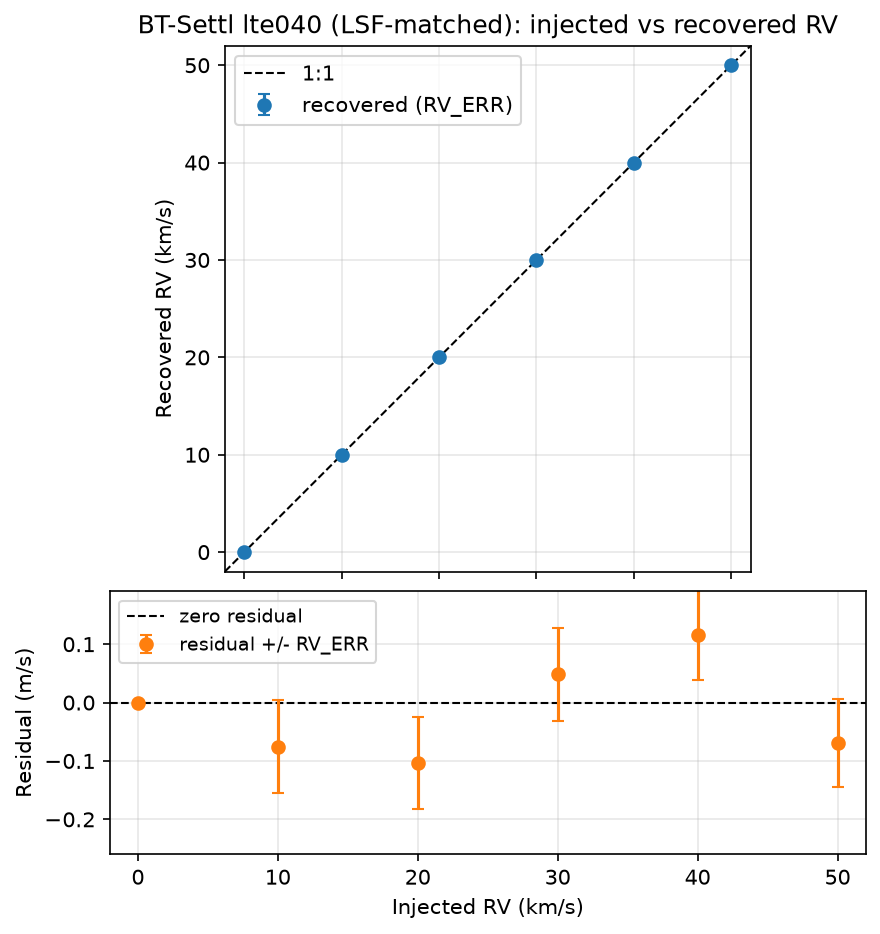

wrote /Users/ckilpatrick/ideal_spectrum_rv_recovery/lte040_lsf_simulated_vs_recovered_rv.png


In [4]:
from hispecdrp.simulations.plotting import plot_ideal_spectrum_rv_recovery

summary = plot_ideal_spectrum_rv_recovery(
    inj_m_s,
    rec_m_s,
    err_m_s,
    title="BT-Settl lte040 (LSF-matched): injected vs recovered RV",
    out_path=OUT / "lte040_lsf_simulated_vs_recovered_rv.png",
)
if summary.get("out_path"):
    print("wrote", summary["out_path"])
